# Технологии ИИ. Лабораторная работа №1
*Выполнил студент группы 6231 Демченко Максим*

# Задача повышения разрешения изображения
В связи с различными ограничениями устройств для фото- и видеосъемки качество получаемых данных может быть недостаточным для решения целого ряда задач, например, для идентификации номеров автомобилей, лиц людей и т.д. Для решения таких проблем используются методы повышения разрешения изображений.

## Постановка задачи 
На вход подается изображение малого разрешения. На выходе получается исходное изображение с большим разрешением.

**Вход**: Изображение низкого разрешения в формате *.png*, *.bmp*, *.jpg*

**Выход**: Исходное изображение с восстановленным высоким разрешением
 
 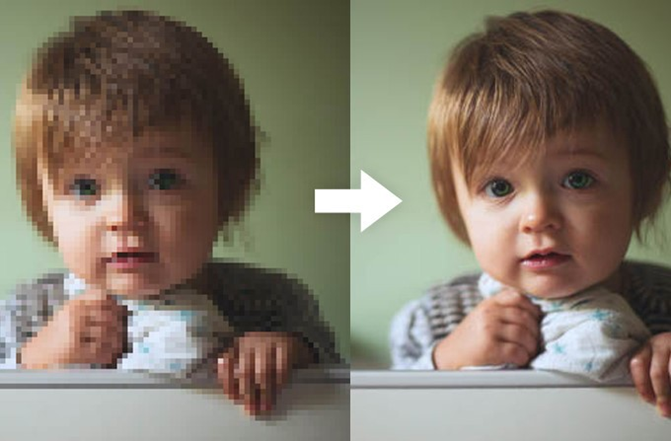

Рисунок 1. Пример изображения в низком разрешении и в повышенном разрешении

## Пример набора данных
Для данной задачи набор данных можно создать самим из имеющихся открытых датасетов (ImageNet, CoCo и т.д.) с помощью инструментов понижения размерности изображений (например, в cv2 метод resize()).

## Предлагаемые архитектуры
• SRGAN (https://arxiv.org/abs/1609.04802)

---
### Источники
"ПРАКТИКУМ
ПО КУРСУ «ТЕХНОЛОГИИ ИСКУССТВЕННОГО ИНТЕЛЛЕКТА И НЕЙРОСЕТЕВОЙ АНАЛИЗ ДАННЫХ»", авторы: Н.С. Давыдов, А.В. Никоноров

## 1. Библиотеки и параметры

In [1]:
import os, time, json, random, zipfile, urllib.request
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import vgg19, VGG19_Weights

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

SCALE = 4              # во сколько раз увеличиваем
HR_TRAIN = 96          # размер HR-куска при обучении (LR будет 24x24)
HR_EVAL = 256          # размер HR-куска при проверке (LR будет 64x64)
BATCH = 16
LR_RATE = 1e-4
PRETRAIN_EPOCHS = 30   # этап 1: SRResNet по MSE
GAN_EPOCHS = 20        # этап 2: SRGAN
ADV_WEIGHT = 1e-4      # вес состязательной ошибки
VGG_WEIGHT = 0.1       # вес VGG-ошибки
LR_GAN = (1e-5, 5e-6)  # скорость обучения генератора и дискриминатора на этапе SRGAN
LIMIT = 0              # 0 = все изображения

DATA_DIR = Path('data')
print('Устройство:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

Устройство: cuda | NVIDIA GeForce RTX 3080


## 2. Данные

Берем COCO val2017 (5000 фотографий, около 780 МБ) и оставляем те, у которых обе стороны не меньше 256 пикселей. Делим на train / val / test = 80 / 10 / 10 % (по именам файлов, seed фиксирован).

- train: случайный кусок 96×96 с отражением, LR — он же, уменьшенный в 4 раза (24×24).
- val / test: центральный кусок 256×256, LR 64×64.

In [2]:
img_dir = DATA_DIR / 'val2017'

names = []
for p in sorted(img_dir.glob('*.jpg')):
    with Image.open(p) as im:
        if min(im.size) >= HR_EVAL:
            names.append(p.name)

random.Random(SEED).shuffle(names)
n = len(names)
splits = {'train': names[:int(n*0.8)], 'val': names[int(n*0.8):int(n*0.9)], 'test': names[int(n*0.9):]}
if LIMIT:
    splits = {k: v[:LIMIT] for k, v in splits.items()}
print({k: len(v) for k, v in splits.items()}, 'из', n)

{'train': 3966, 'val': 496, 'test': 496} из 4958


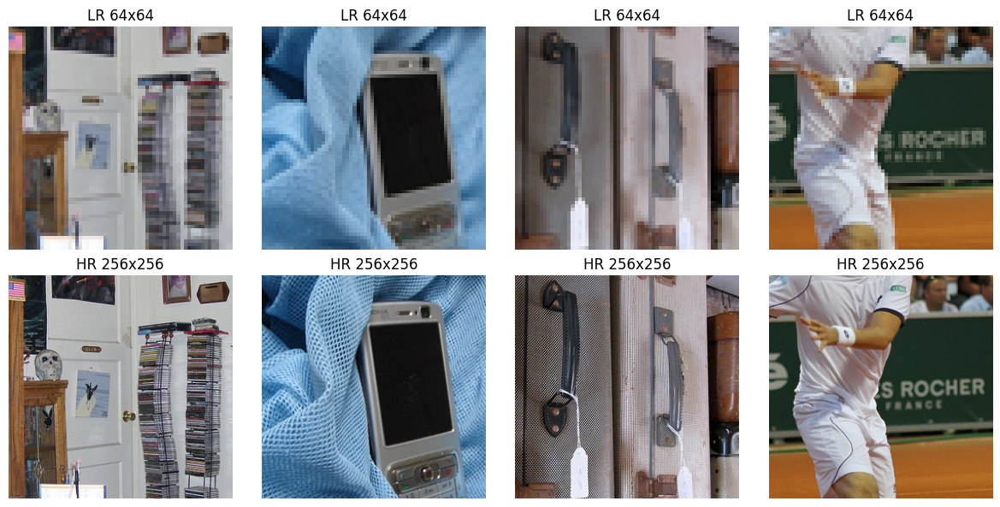

In [3]:
def make_lr(hr_img):
    # HR (PIL) -> LR уменьшением в SCALE раз (bicubic)
    w, h = hr_img.size
    return hr_img.resize((w // SCALE, h // SCALE), Image.BICUBIC)

class SRDataset(Dataset):
    def __init__(self, files, train):
        self.files, self.train = files, train
        self.size = HR_TRAIN if train else HR_EVAL

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img = Image.open(img_dir / self.files[i]).convert('RGB')
        w, h = img.size
        s = self.size
        if self.train:
            x, y = random.randint(0, w - s), random.randint(0, h - s)
        else:
            x, y = (w - s) // 2, (h - s) // 2
        hr = img.crop((x, y, x + s, y + s))
        if self.train and random.random() < 0.5:
            hr = hr.transpose(Image.FLIP_LEFT_RIGHT)
        lr = make_lr(hr)
        to_t = lambda im: torch.from_numpy(np.array(im)).permute(2, 0, 1).float() / 255
        return to_t(lr), to_t(hr)

train_ds, val_ds, test_ds = (SRDataset(splits['train'], True), SRDataset(splits['val'], False), SRDataset(splits['test'], False))
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k in range(4):
    lr, hr = val_ds[k]
    axes[0, k].imshow(lr.permute(1, 2, 0)); axes[0, k].set_title('LR 64x64')
    axes[1, k].imshow(hr.permute(1, 2, 0)); axes[1, k].set_title('HR 256x256')
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Метрики

Сравниваем восстановленную картинку $\hat{y}$ с настоящей HR-картинкой $y$, чем больше значение, тем лучше.

**PSNR** (дБ):

$$\mathrm{MSE} = \frac{1}{N}\sum_{i=1}^{N}(\hat{y}_i - y_i)^2, \qquad \mathrm{PSNR} = 10\log_{10}\frac{\mathrm{MAX}^2}{\mathrm{MSE}}$$

$N$ — число значений пикселей, $\mathrm{MAX}=255$.

**SSIM** (от 0 до 1) считается по окнам:

$$\mathrm{SSIM} = \frac{(2\mu_x\mu_y + C_1)(2\sigma_{xy} + C_2)}{(\mu_x^2 + \mu_y^2 + C_1)(\sigma_x^2 + \sigma_y^2 + C_2)}$$

$\mu$ — средние в окне, $\sigma^2$ — дисперсии, $\sigma_{xy}$ — ковариация, $C_1, C_2$ — малые константы.

**Резкость** — дисперсия лапласиана серого изображения: чем больше, тем больше четких границ. Нужна только для сравнения «размыто / четко», ориентир — резкость настоящих HR.

PSNR и SSIM считаем функциями `skimage.metrics` по RGB (uint8). На val во время обучения PSNR считаем на GPU по той же формуле.

In [2]:
def sharpness(img_u8):
    gray = cv2.cvtColor(img_u8, cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()

def to_u8(t):
    # тензор (B,3,H,W) в [0,1] -> массив uint8 (B,H,W,3)
    return (t.clamp(0, 1) * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()

def psnr_gpu(sr, hr):
    mse = ((sr.clamp(0, 1) - hr) ** 2).mean(dim=(1, 2, 3))
    return (10 * torch.log10(1 / mse.clamp_min(1e-10))).sum().item()

@torch.no_grad()
def val_psnr(G):
    G.eval()
    total = 0.0
    for lr, hr in val_loader:
        total += psnr_gpu(G(lr.to(device)), hr.to(device))
    return total / len(val_ds)

def metrics_table(sr_u8, hr_u8):
    # средние PSNR, SSIM и резкость по набору картинок
    p = [peak_signal_noise_ratio(h, s, data_range=255) for s, h in zip(sr_u8, hr_u8)]
    s = [structural_similarity(h, s_, channel_axis=2, data_range=255) for s_, h in zip(sr_u8, hr_u8)]
    sh = [sharpness(x) for x in sr_u8]
    return float(np.mean(p)), float(np.mean(s)), float(np.mean(sh))

## 4. Базовый вариант: bicubic

Точка отсчета: обычное увеличение без нейросети.

In [5]:
# собираем тестовую выборку в память: LR (float), HR (uint8)
test_lr, test_hr = [], []
for i in range(len(test_ds)):
    lr, hr = test_ds[i]
    test_lr.append(lr); test_hr.append((hr * 255).round().byte().permute(1, 2, 0).numpy())
test_lr = torch.stack(test_lr); test_hr = np.stack(test_hr)

def bicubic_up(lr_batch):
    return F.interpolate(lr_batch, scale_factor=SCALE, mode='bicubic', align_corners=False)

results, preds = {}, {}
preds['Bicubic'] = to_u8(bicubic_up(test_lr))
results['HR (эталон)'] = (None, None, float(np.mean([sharpness(x) for x in test_hr])))
results['Bicubic'] = metrics_table(preds['Bicubic'], test_hr)
print('Bicubic: PSNR=%.2f SSIM=%.4f резкость=%.1f' % results['Bicubic'])
print('Резкость эталона: %.1f' % results['HR (эталон)'][2])

Bicubic: PSNR=23.52 SSIM=0.6607 резкость=20.8
Резкость эталона: 3172.1


**Вывод.** Bicubic дает PSNR 23.52 дБ и SSIM 0.661. С этими числами сравниваем нейросети.

## 5. Сеть

Архитектура SRGAN. **Генератор (SRResNet):** свертка 9×9, 16 остаточных блоков, два слоя PixelShuffle ×2 (итого ×4). **Дискриминатор:** 8 сверток 3×3 (64 → 512 каналов) и два полносвязных слоя, на выходе одно число «настоящая / сгенерированная». **VGG-loss:** MSE между признаками (relu5_4) предобученной VGG19 для SR и HR.

In [3]:
class ResBlock(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1), nn.BatchNorm2d(ch), nn.PReLU(),
            nn.Conv2d(ch, ch, 3, padding=1), nn.BatchNorm2d(ch))
    def forward(self, x):
        return x + self.body(x)

class Generator(nn.Module):
    def __init__(self, n_blocks=16, ch=64):
        super().__init__()
        self.head = nn.Sequential(nn.Conv2d(3, ch, 9, padding=4), nn.PReLU())
        self.blocks = nn.Sequential(*[ResBlock(ch) for _ in range(n_blocks)])
        self.mid = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1), nn.BatchNorm2d(ch))
        up = []
        for _ in range(2):   # два раза x2 = x4
            up += [nn.Conv2d(ch, ch * 4, 3, padding=1), nn.PixelShuffle(2), nn.PReLU()]
        self.up = nn.Sequential(*up)
        self.tail = nn.Conv2d(ch, 3, 9, padding=4)

    def forward(self, x):
        h = self.head(x)
        h = h + self.mid(self.blocks(h))
        return self.tail(self.up(h))

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        cfg = [(64, 1), (64, 2), (128, 1), (128, 2), (256, 1), (256, 2), (512, 1), (512, 2)]
        layers, c_in = [], 3
        for i, (c_out, stride) in enumerate(cfg):
            layers.append(nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1))
            if i > 0:
                layers.append(nn.BatchNorm2d(c_out))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(512 * 6 * 6, 1024), nn.LeakyReLU(0.2, inplace=True), nn.Linear(1024, 1))
    def forward(self, x):
        return self.classifier(self.features(x)).flatten()

class VGGLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.vgg = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).features[:36].eval()   # до relu5_4
        for p in self.vgg.parameters():
            p.requires_grad = False
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, sr, hr):
        return F.mse_loss(self.vgg((sr - self.mean) / self.std), self.vgg((hr - self.mean) / self.std))

G = Generator().to(device)
print('Параметров в генераторе: %.2f млн, в дискриминаторе: %.2f млн' % (
    sum(p.numel() for p in G.parameters()) / 1e6, sum(p.numel() for p in Discriminator().parameters()) / 1e6))
print('Проверка размеров:', tuple(torch.zeros(2, 3, 24, 24).shape), '->', tuple(G(torch.zeros(2, 3, 24, 24, device=device)).shape))

Параметров в генераторе: 1.55 млн, в дискриминаторе: 23.57 млн


Проверка размеров: (2, 3, 24, 24) -> (2, 3, 96, 96)


## 6. Этап 1. SRResNet

Обучаем генератор отдельно по MSE (Adam, `lr=1e-4`), сохраняем веса с лучшим PSNR на val.

эпоха  1: MSE=0.01958  val PSNR=20.67 дБ  (20 с)


эпоха  2: MSE=0.00926  val PSNR=22.03 дБ  (40 с)


эпоха  3: MSE=0.00772  val PSNR=22.46 дБ  (60 с)


эпоха  4: MSE=0.00733  val PSNR=22.58 дБ  (79 с)


эпоха  5: MSE=0.00664  val PSNR=22.93 дБ  (100 с)


...

эпоха 26: MSE=0.00509  val PSNR=24.16 дБ  (512 с)


эпоха 27: MSE=0.00493  val PSNR=24.14 дБ  (531 с)


эпоха 28: MSE=0.00500  val PSNR=24.22 дБ  (550 с)


эпоха 29: MSE=0.00500  val PSNR=24.13 дБ  (569 с)


эпоха 30: MSE=0.00508  val PSNR=24.19 дБ  (588 с)


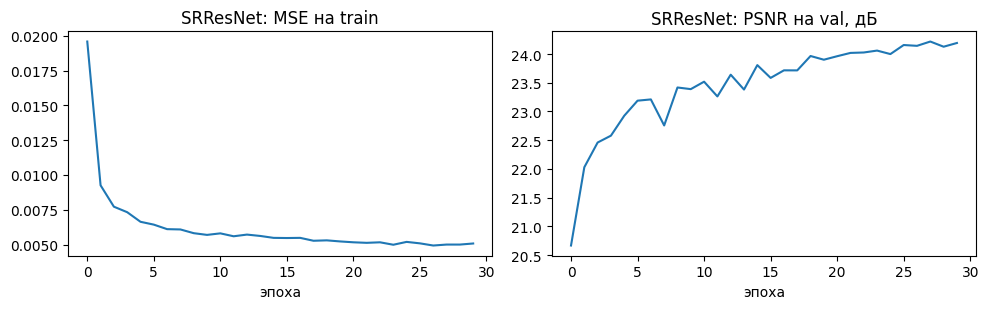

In [7]:
Path('weights').mkdir(exist_ok=True)
G = Generator().to(device)
opt = torch.optim.Adam(G.parameters(), lr=LR_RATE)
hist_pre = {'mse': [], 'val_psnr': []}
best = -1
t0 = time.time()
for ep in range(1, PRETRAIN_EPOCHS + 1):
    G.train(); tot = 0.0
    for lr, hr in train_loader:
        lr, hr = lr.to(device), hr.to(device)
        loss = F.mse_loss(G(lr), hr)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item()
    hist_pre['mse'].append(tot / len(train_loader))
    hist_pre['val_psnr'].append(val_psnr(G))
    if hist_pre['val_psnr'][-1] > best:
        best = hist_pre['val_psnr'][-1]; torch.save(G.state_dict(), 'weights/lr1_srresnet.pt')
    print(f'эпоха {ep:2d}: MSE={hist_pre["mse"][-1]:.5f}  val PSNR={hist_pre["val_psnr"][-1]:.2f} дБ  ({time.time()-t0:.0f} с)')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist_pre['mse']); ax[0].set_title('SRResNet: MSE на train'); ax[0].set_xlabel('эпоха')
ax[1].plot(hist_pre['val_psnr']); ax[1].set_title('SRResNet: PSNR на val, дБ'); ax[1].set_xlabel('эпоха')
plt.tight_layout(); plt.show()

**Вывод.** MSE падает, PSNR на val растет с 20.7 до 24.2 дБ и к 30-й эпохе почти перестает расти. Это выше, чем у bicubic (23.52 дБ на тесте), значит, обучение работает.

## 7. Этап 2. SRGAN

Дообучаем лучший SRResNet вместе с дискриминатором. $D$ учится отличать настоящие HR от сгенерированных, $G$ — обманывать $D$ и сохранять содержание:

$$L_G = L_{MSE} + 0.1\, L_{VGG} + 10^{-4}\, L_{adv}$$

$L_{MSE}$ — ошибка по пикселям, $L_{VGG}$ — MSE VGG-признаков, $L_{adv}$ — насколько $D$ принимает SR за настоящую картинку. Скорость обучения мала: `1e-5` у $G$ и `5e-6` у $D$. Берем веса последней эпохи. Пиксельная MSE добавлена в ошибку потому, что без нее и с большим весом $L_{adv}$ на картинках появлялась цветная сетка, и качество падало ниже bicubic (подробнее в выводах).

эпоха  1: VGG=0.5227 adv=2.781 D=0.254 D(real)=0.80 D(fake)=0.19 val PSNR=24.11 (32 с)


эпоха  2: VGG=0.5186 adv=5.778 D=0.022 D(real)=0.98 D(fake)=0.02 val PSNR=24.00 (63 с)


эпоха  3: VGG=0.5116 adv=6.973 D=0.029 D(real)=0.98 D(fake)=0.02 val PSNR=23.99 (95 с)


эпоха  4: VGG=0.5182 adv=7.715 D=0.009 D(real)=0.99 D(fake)=0.01 val PSNR=23.95 (132 с)


эпоха  5: VGG=0.5009 adv=9.223 D=0.024 D(real)=0.99 D(fake)=0.01 val PSNR=23.94 (168 с)


...

эпоха 16: VGG=0.4878 adv=10.832 D=0.000 D(real)=1.00 D(fake)=0.00 val PSNR=23.78 (555 с)


эпоха 17: VGG=0.4944 adv=10.778 D=0.003 D(real)=1.00 D(fake)=0.00 val PSNR=23.80 (586 с)


эпоха 18: VGG=0.4956 adv=11.316 D=0.002 D(real)=1.00 D(fake)=0.00 val PSNR=23.84 (619 с)


эпоха 19: VGG=0.4928 adv=11.575 D=0.002 D(real)=1.00 D(fake)=0.00 val PSNR=23.86 (652 с)


эпоха 20: VGG=0.4929 adv=11.143 D=0.000 D(real)=1.00 D(fake)=0.00 val PSNR=23.86 (686 с)


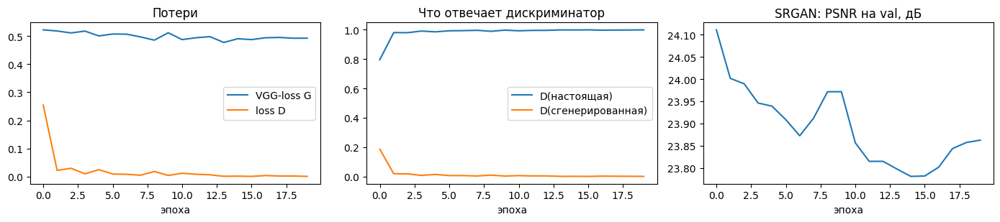

In [8]:
G = Generator().to(device)
G.load_state_dict(torch.load('weights/lr1_srresnet.pt', map_location=device))
D = Discriminator().to(device)
vgg_loss = VGGLoss().to(device)
bce = nn.BCEWithLogitsLoss()
opt_g = torch.optim.Adam(G.parameters(), lr=LR_GAN[0])
opt_d = torch.optim.Adam(D.parameters(), lr=LR_GAN[1])
hist_gan = {'g_vgg': [], 'g_adv': [], 'd_loss': [], 'p_real': [], 'p_fake': [], 'val_psnr': []}
t0 = time.time()
for ep in range(1, GAN_EPOCHS + 1):
    G.train(); D.train()
    acc = np.zeros(5)
    for lr, hr in train_loader:
        lr, hr = lr.to(device), hr.to(device)
        sr = G(lr)
        # 1) шаг дискриминатора
        d_real, d_fake = D(hr), D(sr.detach())
        loss_d = (bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))) / 2
        opt_d.zero_grad(); loss_d.backward(); opt_d.step()
        # 2) шаг генератора
        d_out = D(sr)
        l_vgg, l_adv = vgg_loss(sr, hr), bce(d_out, torch.ones_like(d_out))
        loss_g = F.mse_loss(sr, hr) + VGG_WEIGHT * l_vgg + ADV_WEIGHT * l_adv
        opt_g.zero_grad(); loss_g.backward(); opt_g.step()
        acc += [l_vgg.item(), l_adv.item(), loss_d.item(), torch.sigmoid(d_real).mean().item(), torch.sigmoid(d_fake).mean().item()]
    acc /= len(train_loader)
    for k, v in zip(['g_vgg', 'g_adv', 'd_loss', 'p_real', 'p_fake'], acc):
        hist_gan[k].append(float(v))
    hist_gan['val_psnr'].append(val_psnr(G))
    print(f'эпоха {ep:2d}: VGG={acc[0]:.4f} adv={acc[1]:.3f} D={acc[2]:.3f} D(real)={acc[3]:.2f} D(fake)={acc[4]:.2f} val PSNR={hist_gan["val_psnr"][-1]:.2f} ({time.time()-t0:.0f} с)')
torch.save(G.state_dict(), 'weights/lr1_srgan.pt')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].plot(hist_gan['g_vgg'], label='VGG-loss G'); ax[0].plot(hist_gan['d_loss'], label='loss D'); ax[0].legend(); ax[0].set_title('Потери'); ax[0].set_xlabel('эпоха')
ax[1].plot(hist_gan['p_real'], label='D(настоящая)'); ax[1].plot(hist_gan['p_fake'], label='D(сгенерированная)'); ax[1].legend(); ax[1].set_title('Что отвечает дискриминатор'); ax[1].set_xlabel('эпоха')
ax[2].plot(hist_gan['val_psnr']); ax[2].set_title('SRGAN: PSNR на val, дБ'); ax[2].set_xlabel('эпоха')
plt.tight_layout(); plt.show()

**Вывод.** Дискриминатор с первых эпох почти безошибочно отличает SR от HR (D(real) ≈ 1, D(fake) ≈ 0). PSNR на val снижается с 24.11 до ≈23.8 дБ: GAN-этап немного жертвует точностью по пикселям ради резкости.

## 8. Результаты на тесте

Метод           PSNR, дБ     SSIM   Резкость
Bicubic            23.52   0.6607       20.8
SRResNet           24.12   0.6827       91.0
SRGAN              23.77   0.6514      164.8
HR (эталон)            -        -     3172.1


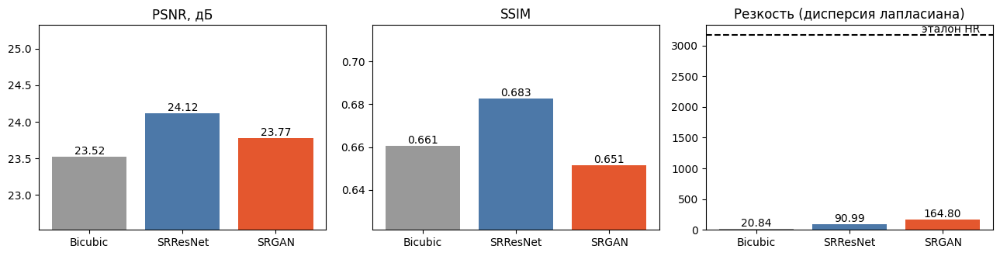

In [9]:
@torch.no_grad()
def run_generator(weights):
    g = Generator().to(device)
    g.load_state_dict(torch.load(weights, map_location=device)); g.eval()
    out = [g(test_lr[i:i + BATCH].to(device)) for i in range(0, len(test_lr), BATCH)]
    return to_u8(torch.cat(out))

preds['SRResNet'] = run_generator('weights/lr1_srresnet.pt')
preds['SRGAN'] = run_generator('weights/lr1_srgan.pt')
results['SRResNet'] = metrics_table(preds['SRResNet'], test_hr)
results['SRGAN'] = metrics_table(preds['SRGAN'], test_hr)

print(f'{"Метод":<14}{"PSNR, дБ":>10}{"SSIM":>9}{"Резкость":>11}')
for name in ['Bicubic', 'SRResNet', 'SRGAN', 'HR (эталон)']:
    p, s, sh = results[name]
    print(f'{name:<14}{(f"{p:.2f}" if p else "-"):>10}{(f"{s:.4f}" if s else "-"):>9}{sh:>11.1f}')
json.dump({k: list(v) for k, v in results.items()}, open('weights/lr1_results.json', 'w'))

names3 = ['Bicubic', 'SRResNet', 'SRGAN']
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, idx, title in zip(ax, [0, 1, 2], ['PSNR, дБ', 'SSIM', 'Резкость (дисперсия лапласиана)']):
    vals = [results[n][idx] for n in names3]
    a.bar(names3, vals, color=['#999999', '#4C78A8', '#E4572E']); a.set_title(title)
    for i, v in enumerate(vals): a.text(i, v, f'{v:.2f}' if idx != 1 else f'{v:.3f}', ha='center', va='bottom')
ax[2].axhline(results['HR (эталон)'][2], color='k', ls='--'); ax[2].text(2.4, results['HR (эталон)'][2], 'эталон HR', ha='right', va='bottom')
ax[0].set_ylim(min(results[n][0] for n in names3) - 1, None); ax[1].set_ylim(min(results[n][1] for n in names3) - 0.03, None)
plt.tight_layout(); plt.show()

**Вывод.** SRResNet лучше bicubic: +0.6 дБ PSNR и +0.022 SSIM. SRGAN по PSNR тоже лучше bicubic (23.77 против 23.52), по SSIM чуть хуже (0.651 против 0.661) и уступает SRResNet по обеим метрикам, зато резче всех (резкость 165 против 91 у SRResNet и 21 у bicubic; у эталона 3172).

In [11]:
# проверка на утечку данных и переобучение
a, b, c = set(splits['train']), set(splits['val']), set(splits['test'])
print('Общих файлов: train и val -', len(a & b), ', train и test -', len(a & c), ', val и test -', len(b & c))

@torch.no_grad()
def psnr_ssim_on(files, weights, n=200):
    # PSNR и SSIM на первых n картинках выборки (центральные куски, как на тесте)
    g = Generator().to(device); g.load_state_dict(torch.load(weights, map_location=device)); g.eval()
    ds, ps, ss = SRDataset(files[:n], False), [], []
    for i in range(0, len(ds), BATCH):
        items = [ds[j] for j in range(i, min(i + BATCH, len(ds)))]
        sr = to_u8(g(torch.stack([t[0] for t in items]).to(device)))
        for s_, (_, hr) in zip(sr, items):
            h = to_u8(hr.unsqueeze(0))[0]
            ps.append(peak_signal_noise_ratio(h, s_, data_range=255)); ss.append(structural_similarity(h, s_, channel_axis=2, data_range=255))
    return np.mean(ps), np.mean(ss)

print(f'{"":<10}{"train":>16}{"val":>16}{"test":>16}   (PSNR / SSIM)')
for name, w in [('SRResNet', 'weights/lr1_srresnet.pt'), ('SRGAN', 'weights/lr1_srgan.pt')]:
    row = [psnr_ssim_on(splits[k], w) for k in ('train', 'val', 'test')]
    print(f'{name:<10}' + ''.join(f'{p:>10.2f} / {s:.3f}' for p, s in row))

Общих файлов: train и val - 0 , train и test - 0 , val и test - 0
                     train             val            test   (PSNR / SSIM)


SRResNet       23.78 / 0.687     24.09 / 0.678     24.23 / 0.682


SRGAN          23.45 / 0.653     23.74 / 0.647     23.89 / 0.651


**Вывод.** Файлы train, val и test не пересекаются, а качество на train, val и test почти одинаковое, значит, утечки и переобучения нет.

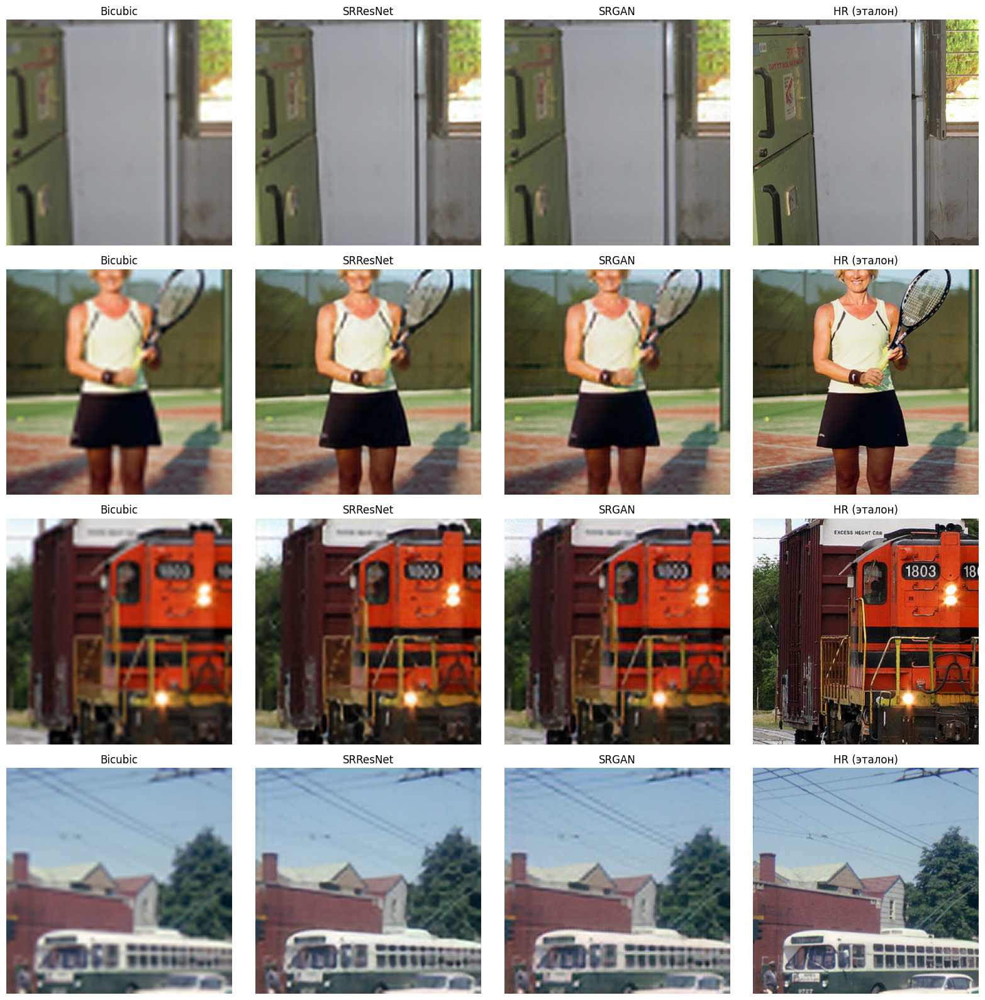

In [12]:
cols = ['Bicubic', 'SRResNet', 'SRGAN']
idxs = [0, 3, 7, 12] if len(test_hr) > 12 else list(range(min(4, len(test_hr))))
fig, axes = plt.subplots(len(idxs), 4, figsize=(16, 4 * len(idxs)))
for r, i in enumerate(idxs):
    for c, (name, img) in enumerate([(n, preds[n][i]) for n in cols] + [('HR (эталон)', test_hr[i])]):
        axes[r, c].imshow(img); axes[r, c].set_title(name); axes[r, c].axis('off')
plt.tight_layout(); plt.show()

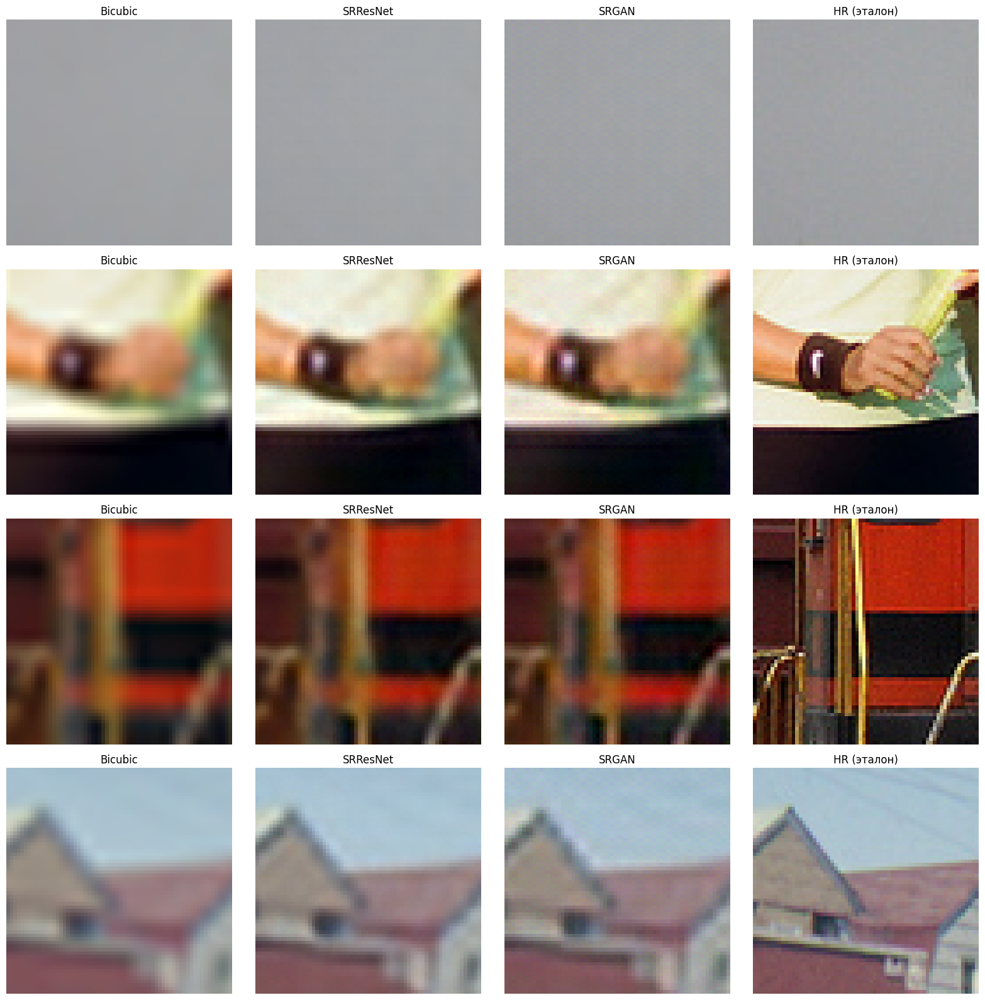

In [13]:
# те же картинки, но приближены: вырезаем кусок 64x64 пикселя и растягиваем без сглаживания
fig, axes = plt.subplots(len(idxs), 4, figsize=(16, 4 * len(idxs)))
for r, i in enumerate(idxs):
    for c, (name, img) in enumerate([(n, preds[n][i]) for n in cols] + [('HR (эталон)', test_hr[i])]):
        axes[r, c].imshow(img[96:160, 96:160], interpolation='nearest'); axes[r, c].set_title(name); axes[r, c].axis('off')
plt.tight_layout(); plt.show()

**Вывод.** SRResNet и SRGAN четче bicubic, у SRGAN контуры заметнее, цветной сетки нет. Тонкие детали (надписи, провода) все равно не восстанавливаются, до эталона далеко.

## 9. Свои фотографии

Берем свои фотографии из папки `photos` целиком, без обрезки. Большие картинки обрабатываем по кускам, иначе не хватает видеопамяти. Сначала просто увеличиваем в 4 раза (9.1), потом уменьшаем в 4 раза и возвращаем обратно, чтобы сравнить с оригиналом (9.2). Результаты ×4 сохраняются в `photos/results`, на графиках показаны увеличенные фрагменты.

In [4]:
@torch.no_grad()
def upscale(g, img, tile=128, pad=8):
    # img: uint8 (H, W, 3) -> uint8 (4H, 4W, 3); обрабатываем кусками tile x tile с запасом pad по краям
    h, w = img.shape[:2]
    padded = np.pad(img, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')
    out = np.zeros((h * SCALE, w * SCALE, 3), np.uint8)
    for y in range(0, h, tile):
        for x in range(0, w, tile):
            part = padded[y:y + tile + 2 * pad, x:x + tile + 2 * pad]
            t = torch.from_numpy(part).permute(2, 0, 1).float().unsqueeze(0).div(255).to(device)
            sr = to_u8(g(t))[0][pad * SCALE:-pad * SCALE, pad * SCALE:-pad * SCALE]
            out[y * SCALE:y * SCALE + sr.shape[0], x * SCALE:x * SCALE + sr.shape[1]] = sr
    return out

def load_photo(path, box=None):
    im = Image.open(path).convert('RGB')
    if box:
        im = im.crop(box)
    w, h = im.size
    return np.array(im.crop((0, 0, w - w % SCALE, h - h % SCALE)))

def load_generator(weights):
    g = Generator().to(device)
    g.load_state_dict(torch.load(weights, map_location=device)); g.eval()
    return g

g_res, g_gan = load_generator('weights/lr1_srresnet.pt'), load_generator('weights/lr1_srgan.pt')

# имя: (файл, рамка фрагмента, область для просмотра x0, y0, x1, y1)
photos = {
    'Кот':    ('photos/cat.jpg', None, (680, 300, 980, 525)),
    'Залив':  ('photos/sea.jpg', None, (1150, 430, 1450, 655)),
    'Камень': ('photos/DSC00687.JPG', None, (2550, 850, 2850, 1075)),
}
imgs = {name: load_photo(path, box) for name, (path, box, _) in photos.items()}
print({name: img.shape[1::-1] for name, img in imgs.items()})


{'Кот': (2000, 924), 'Залив': (2000, 924), 'Камень': (5184, 2920)}


### 9.1. Увеличение в 4 раза

Кот: 2000x924 -> 8000x3696


Залив: 2000x924 -> 8000x3696


Камень: 5184x2920 -> 20736x11680


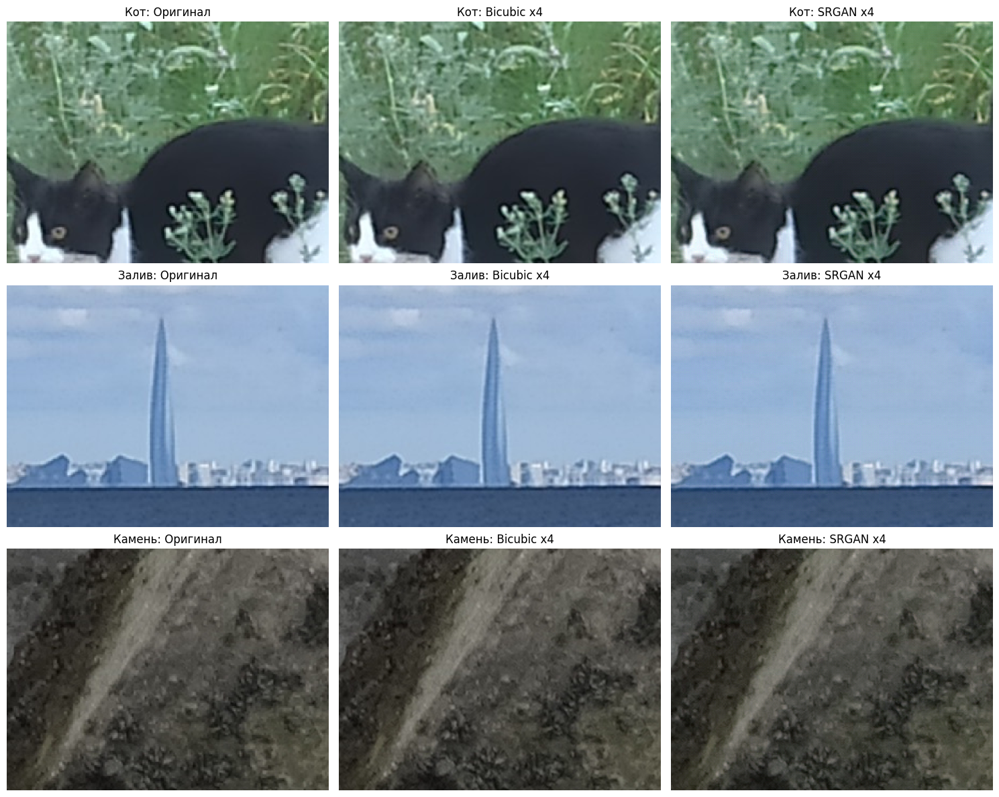

In [5]:
Path('photos/results').mkdir(exist_ok=True)
fig, axes = plt.subplots(len(imgs), 3, figsize=(15, 4 * len(imgs)))
for r, (name, img) in enumerate(imgs.items()):
    x0, y0, x1, y1 = photos[name][2]
    sr = upscale(g_gan, img)
    Image.fromarray(sr).save(f'photos/results/{name}_x4.jpg', quality=95)
    bic = cv2.resize(img, (img.shape[1] * SCALE, img.shape[0] * SCALE), interpolation=cv2.INTER_CUBIC)
    for ax, (title, im) in zip(axes[r], [('Оригинал', img[y0:y1, x0:x1]), ('Bicubic x4', bic[y0 * 4:y1 * 4, x0 * 4:x1 * 4]),
                                         ('SRGAN x4', sr[y0 * 4:y1 * 4, x0 * 4:x1 * 4])]):
        ax.imshow(im, interpolation='nearest'); ax.set_title(f'{name}: {title}'); ax.axis('off')
    print(f'{name}: {img.shape[1]}x{img.shape[0]} -> {sr.shape[1]}x{sr.shape[0]}')
plt.tight_layout(); plt.show()


**Вывод.** Фотографии увеличены целиком в 4 раза (кот и залив до 8000×3696, снимок с камеры до 20736×11680). На увеличенных фрагментах SRGAN и SRResNet чуть четче bicubic; сравнить с настоящим снимком большего размера нечем.

### 9.2. Уменьшили в 4 раза и вернули

Фото     Метод      PSNR, дБ    SSIM


Кот      Bicubic       27.60   0.792


Кот      SRResNet      28.80   0.842


Кот      SRGAN         28.12   0.813


Залив    Bicubic       34.76   0.919


Залив    SRResNet      33.96   0.926


Залив    SRGAN         33.44   0.837


Камень   Bicubic       37.19   0.900


Камень   SRResNet      37.55   0.909


Камень   SRGAN         36.44   0.885


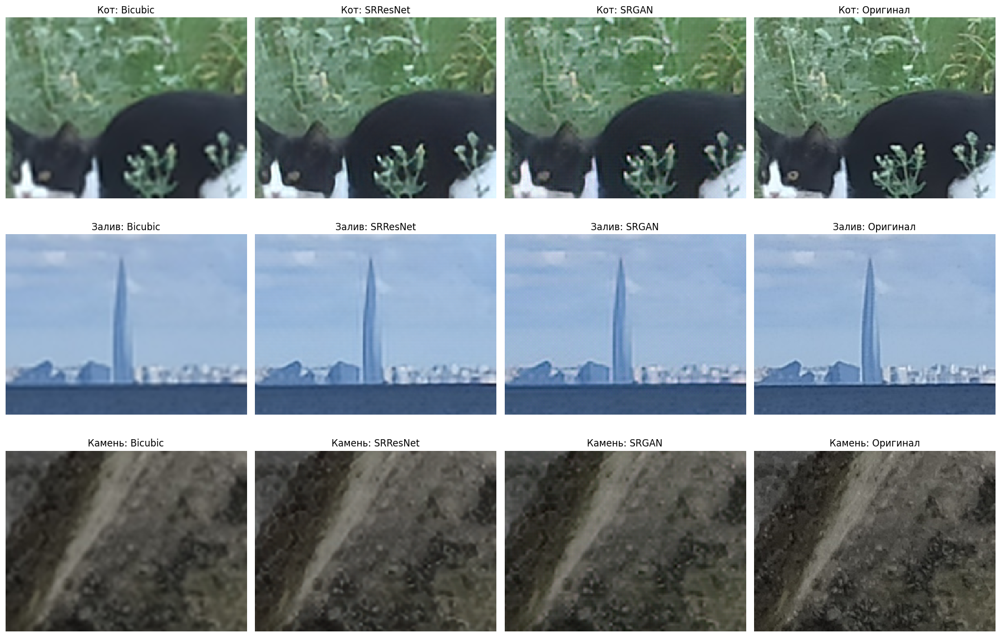

In [6]:
fig, axes = plt.subplots(len(imgs), 4, figsize=(18, 4 * len(imgs)))
print(f'{"Фото":<9}{"Метод":<10}{"PSNR, дБ":>9}{"SSIM":>8}')
for r, (name, img) in enumerate(imgs.items()):
    x0, y0, x1, y1 = photos[name][2]
    h, w = img.shape[:2]
    small = np.array(Image.fromarray(img).resize((w // SCALE, h // SCALE), Image.BICUBIC))
    restored = {'Bicubic': cv2.resize(small, (w, h), interpolation=cv2.INTER_CUBIC),
                'SRResNet': upscale(g_res, small), 'SRGAN': upscale(g_gan, small)}
    for k, (title, im) in enumerate(list(restored.items()) + [('Оригинал', img)]):
        if title != 'Оригинал':
            print(f'{name:<9}{title:<10}{peak_signal_noise_ratio(img, im, data_range=255):>9.2f}{structural_similarity(img, im, channel_axis=2, data_range=255):>8.3f}')
        axes[r, k].imshow(im[y0:y1, x0:x1], interpolation='nearest'); axes[r, k].set_title(f'{name}: {title}'); axes[r, k].axis('off')
plt.tight_layout(); plt.show()


**Вывод.** SRResNet лучше bicubic на всех фото, кроме залива с почти ровным небом, где по PSNR bicubic лучше обеих сетей (кот 28.8 против 27.6 дБ, камень 37.6 против 37.2). SRGAN лучше bicubic только у кота (28.1 против 27.6), у камня хуже (36.4 против 37.2).

## 10. Выводы

| | PSNR, дБ | SSIM |
|---|---|---|
| Bicubic | 23.52 | 0.661 |
| SRResNet | 24.12 | 0.683 |
| SRGAN, первые тесты | 21.11 | 0.496 |
| SRGAN, после статей | 23.77 | 0.651 |

По моим первым тестам с входными параметрами: скорость обучения 1e-4 у генератора и дискриминатора, в ошибке генератора только VGG-часть и состязательная с весом 1e-3, 20 эпох, получились следующие результаты: PSNR 21.11 дБ и SSIM 0.496, то есть хуже bicubic (23.52 дБ и 0.661), на картинках цветная сетка, а дискриминатор почти всегда безошибочно отличал SR от HR (D(real) ≈ 1, D(fake) ≈ 0). Обучение 60 эпох вместо 20 почти ничего не изменило (21.45 дБ и 0.504). Эти запуски выполнялись раньше, до чтения статей.

Для улучшения результатов были рассмотрены статьи (папка [papers](papers/), статья про SRGAN) и выбраны лучшие параметры: скорость обучения 1e-5 (в статье вторую половину обучения ведут с 1e-5), в ошибку генератора добавлена пиксельная MSE (в статье есть вариант SRGAN-MSE), вес VGG-ошибки уменьшен до 0.1, чтобы она была сопоставима с MSE (в статье ее масштабируют множителем 1/12.75), вес состязательной ошибки снижен до 1e-4. Веса 0.1 и 1e-4 и скорость обучения дискриминатора 5e-6 я подобрал сам. Благодаря этому получилось добиться лучших результатов: PSNR 23.77 дБ и SSIM 0.651, цветная сетка пропала, по PSNR SRGAN стал лучше bicubic. Но SRResNet (24.12 дБ и 0.683) все равно лучше SRGAN по обеим метрикам: дискриминатор по-прежнему слишком силен и влияет на результат слабо.

На своих фотографиях (уменьшили в 4 раза и вернули) SRResNet лучше bicubic на всех, кроме залива, а SRGAN только на фото кота.